# Singularidades · direcciones que se pierden

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. Qué significa perder rango

El rango cuenta cuántas direcciones cartesianas independientes producen las columnas de `JL`. Tener tres motores no garantiza tres direcciones lineales instantáneas en todas las posturas. Una singularidad depende de la tarea: posición y velocidad completa usan matrices distintas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

def linear_jacobian(q):
    q1, q2, q3 = q
    c1, s1 = np.cos(q1), np.sin(q1)
    c23, s23 = np.cos(q2 + q3), np.sin(q2 + q3)
    rho = l2 * np.cos(q2) + l3 * c23
    height = l2 * np.sin(q2) + l3 * s23
    return np.array([
        [-s1 * rho, -c1 * height, -l3 * c1 * s23],
        [ c1 * rho, -s1 * height, -l3 * s1 * s23],
        [0, rho, l3 * c23],
    ])


def angular_jacobian(q):
    s1, c1 = np.sin(q[0]), np.cos(q[0])
    return np.array([[0, s1, s1], [0, -c1, -c1], [1, 0, 0]])

## 2. Factorizar el determinante

$$\det J_L=-l_2l_3\rho\sin q_3.$$

Como las longitudes son positivas, las familias singulares son $\rho=0$ (efector en el eje de base) y $\sin q_3=0$ (eslabones móviles alineados). La intersección puede reducir aún más el rango. Se comprueban tres posturas concretas.

In [2]:
configurations = {
    "Regular": np.deg2rad([30, 40, -50]),
    "Codo extendido": np.array([0, 0, 0]),
    "Extendido vertical": np.array([0, np.pi/2, 0]),
}
ranks = []
for name, q in configurations.items():
    JL = linear_jacobian(q)
    J = np.vstack([JL, angular_jacobian(q)])
    rho = l2*np.cos(q[1]) + l3*np.cos(q[1] + q[2])
    expected_det = -l2*l3*rho*np.sin(q[2])
    assert np.isclose(np.linalg.det(JL), expected_det, atol=1e-12)
    rank = np.linalg.matrix_rank(JL, tol=1e-10)
    ranks.append(rank)
    print(name, "rango JL:", rank, "rango J:", np.linalg.matrix_rank(J, tol=1e-10))
assert ranks == [3, 2, 1]

Regular rango JL: 3 rango J: 3
Codo extendido rango JL: 2 rango J: 3
Extendido vertical rango JL: 1 rango J: 3


## 3. Acercarse a la singularidad

El menor valor singular `sigma_min` mide la respuesta en la dirección peor transmitida. Cerca de cero, algunas velocidades deseadas requieren velocidades articulares grandes. Se mantiene hombro en 40° y se barre el codo; también se puede cruzar la familia `rho=0`.

No se calcula un determinante de `J` completo: es 6×3. Tampoco se mezclan sus valores singulares con los de `JL`, porque las filas lineales y angulares tienen unidades distintas.

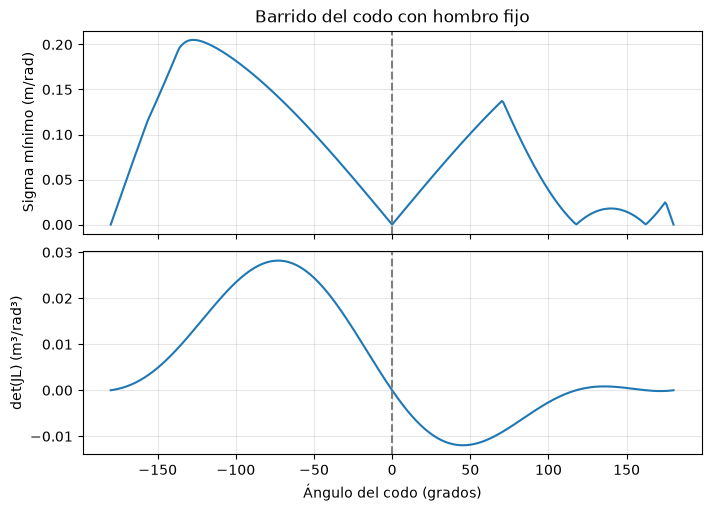

In [3]:
elbow_angles = np.linspace(-np.pi, np.pi, 401)
smallest_values = []
determinants = []
for elbow in elbow_angles:
    JL = linear_jacobian([0, np.deg2rad(40), elbow])
    smallest_values.append(np.linalg.svd(JL, compute_uv=False)[-1])
    determinants.append(np.linalg.det(JL))

fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True, layout="constrained")
axes[0].plot(np.rad2deg(elbow_angles), smallest_values)
axes[0].set(ylabel="Sigma mínimo (m/rad)", title="Barrido del codo con hombro fijo")
axes[1].plot(np.rad2deg(elbow_angles), determinants)
axes[1].set(xlabel="Ángulo del codo (grados)", ylabel="det(JL) (m³/rad³)")
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")
    ax.grid(alpha=0.3)
plt.show()

## 4. La pseudoinversa no crea una dirección perdida

En la extensión horizontal, un error puramente radial no produce una orden de velocidad útil. El objetivo es alcanzable doblando el brazo, pero no puede iniciarse ese desplazamiento con la dirección instantánea pedida por esta ley local.

In [4]:
q = np.zeros(3)
target = np.array([0.50, 0, 0.04])
error = target - position(q)
JL = linear_jacobian(q)
command = np.linalg.pinv(JL) @ error  # ganancia 1/s
print("Error (m):", error)
print("Orden articular (rad/s):", command)
print("Velocidad realmente obtenida (m/s):", JL @ command)
assert np.isclose(np.linalg.norm(error), 0.03)
assert np.allclose(command, 0, atol=1e-12)

Error (m): [-0.03  0.    0.  ]
Orden articular (rad/s): [0. 0. 0.]
Velocidad realmente obtenida (m/s): [0. 0. 0.]


## Lectura y ejercicio

En los ejemplos, `JL` tiene rangos 3, 2 y 1, mientras `J=[JL;Jw]` conserva rango de columna 3. Esto no habilita seis componentes de pose independientes: sólo hay tres entradas articulares.

Mover ligeramente el codo desde cero cambia el problema. Observar `sigma_min` y la orden calculada antes de concluir que desapareció el riesgo. Una pseudoinversa amortiguada puede limitar amplificación, pero tampoco recupera una dirección ausente. **Siguiente:** [trayectorias](../trajectories/README.md) y [control](../control/README.md).